# Projeto Integrador P15
## Demanda diária de bicicletas e condições meteorológicas
**Marlon Caldas Barbosa** · UNIFAP Digital · BDED-2026.1 · Prof. Dr. Adolfo Colares

**Pergunta:** quanto da variação na demanda diária pode ser estimado a partir de calendário, tendência temporal e clima observado? Integração de duas fontes públicas independentes: UCI/Capital Bikeshare e API NASA POWER. Dados reais de 2011–2012; não se trata de previsão antecipada do clima ou de viagens futuras.

## 1. Reprodução integral
Execute `prepare_postgres.ps1` antes deste notebook. Instale `requirements.txt` no kernel escolhido. Uma conexão alternativa pode ser definida por `DATABASE_URL`. O pipeline usa snapshots com hashes por padrão; `--refresh` faz nova coleta. O banco é persistente.

**Fluxo:** UCI CSV + NASA JSON → validação/transformação Python → tabelas PostgreSQL → JOIN SQL → features → validação temporal → modelo → métricas.

In [1]:
from pathlib import Path
import sys,os,json
root=Path.cwd()
if root.name=="notebooks":root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
from src.run_pipeline import run
resultado=run()

{
  "modelo_escolhido": "Ridge",
  "criterio": "Menor RMSE medio em 5 folds temporais; alvo de teste nao participa da selecao",
  "treino": {
    "n": 639,
    "inicio": "2011-01-01",
    "fim": "2012-09-30"
  },
  "teste": {
    "n": 92,
    "inicio": "2012-10-01",
    "fim": "2012-12-31",
    "rmse": 1251.4296432075805,
    "mae": 848.9812963177056,
    "r2": 0.5749610034198108
  },
  "baseline_teste": {
    "rmse": 2063.115915223999,
    "mae": 1755.0226236646931,
    "r2": -0.155215906037389
  },
  "reducao_rmse_vs_baseline_pct": 39.3427371689046,
  "features_antes_encoding": 17,
  "features_apos_encoding": 36,
  "ablacao": {
    "ridge_calendario_cv_rmse": 1191.6394653427476,
    "ridge_calendario_clima_cv_rmse": 931.4168998896068,
    "objetivo": "Medir contribuicao da fonte meteorologica em validacao temporal de treino; nao selecionar pelo teste."
  },
  "folds": [
    {
      "fold": 1,
      "treino_inicio": "2011-01-01",
      "treino_fim": "2011-07-08",
      "validacao_inic

## 2. Coleta, procedência e qualidade
UCI: Fanaee-T, H. (2013), Bike Sharing, DOI [10.24432/C5W894](https://doi.org/10.24432/C5W894), licença CC BY 4.0. NASA POWER Daily API v2.10.0, acesso em 10/10/2026, MERRA2/POWER. Atribuição: dados do projeto POWER, NASA Langley Research Center, financiado pela NASA Earth Science Division. [Documentação da API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/) e [guia de referência](https://power.larc.nasa.gov/docs/referencing/).

O snapshot NASA utiliza hora solar local; a associação pela data nominal é uma aproximação diária ao calendário UCI. O ponto meteorológico representa a cidade, não cada estação. Essas limitações estão em `docs/FONTES.md`. Não se introduzem erros artificiais nos dados reais.

In [2]:
import pandas as pd
proveniencia=json.loads((root/"data/raw/proveniencia.json").read_text(encoding="utf-8"))
display(pd.DataFrame(proveniencia).T)
display(json.loads((root/"reports/metrics/etl.json").read_text(encoding="utf-8")))

,url,sha256,bytes,registrado_em_utc,nota,arquivo_pai
bike_sharing.zip,https://archive.ics.uci.edu/static/public/275/...,b70182d0d0508e9abbb79306ce5c0cec34869000f82201...,279992,2026-10-10T17:52:29.514602+00:00,Data de registro do snapshot local; as fontes ...,NaN
nasa_power.json,https://power.larc.nasa.gov/api/temporal/daily...,a1072d741674d0eb27ab96e2ad6a43675150a369765011...,48287,2026-10-10T17:52:29.514602+00:00,Data de registro do snapshot local; as fontes ...,NaN
day.csv,NaN,a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff1...,57569,NaN,NaN,bike_sharing.zip


{'antes': {'bicicletas': {'linhas': 731, 'duplicatas_data': 0, 'nulos': 0},
  'clima': {'linhas': 731,
   'sentinelas': 0,
   'nulos_apos_validacao': 0,
   'duplicatas_data': 0}},
 'depois': {'calendario': 731, 'demanda': 731, 'clima': 731},
 'linhas_removidas': 0,
 'politica': 'Datas e contagens invalidas interrompem ETL; clima invalido vira nulo; imputacao por mediana exclusivamente no treino.'}

## 3. Modelagem e integração no PostgreSQL
`localidade` e `calendario` são dimensões; `demanda_diaria` e `clima_diario` são fatos no grão localidade/data; `carga_fonte` registra procedência. PK, FK e CHECKs validam o relacionamento e as contagens. A view abaixo integra fontes por localidade e data, excluindo parcelas do alvo. A carga é transacional e idempotente.

In [3]:
print((root/"sql/schema.sql").read_text())
from src.etl import connect
with connect() as conn:
    cur=conn.execute("SELECT * FROM mobilidade.dataset_integrado ORDER BY data LIMIT 5")
    display(pd.DataFrame(cur.fetchall(),columns=[c.name for c in cur.description]))
    display(conn.execute("SELECT fonte, linhas, sha256 FROM mobilidade.carga_fonte ORDER BY fonte").fetchall())
print((root/"reports/metrics/postgresql.json").read_text(encoding="utf-8"))

CREATE SCHEMA IF NOT EXISTS mobilidade;
CREATE TABLE IF NOT EXISTS mobilidade.localidade (
    localidade_id SMALLINT PRIMARY KEY,
    nome TEXT NOT NULL UNIQUE,
    latitude DOUBLE PRECISION NOT NULL CHECK(latitude BETWEEN -90 AND 90),
    longitude DOUBLE PRECISION NOT NULL CHECK(longitude BETWEEN -180 AND 180)
);
CREATE TABLE IF NOT EXISTS mobilidade.calendario (
    data DATE PRIMARY KEY,
    ano SMALLINT NOT NULL,
    mes SMALLINT NOT NULL CHECK(mes BETWEEN 1 AND 12),
    dia_semana SMALLINT NOT NULL CHECK(dia_semana BETWEEN 0 AND 6),
    feriado BOOLEAN NOT NULL,
    dia_util BOOLEAN NOT NULL
);
CREATE TABLE IF NOT EXISTS mobilidade.demanda_diaria (
    localidade_id SMALLINT NOT NULL REFERENCES mobilidade.localidade,
    data DATE NOT NULL REFERENCES mobilidade.calendario,
    viagens INTEGER NOT NULL CHECK(viagens >= 0),
    casuais INTEGER NOT NULL CHECK(casuais >= 0),
    cadastrados INTEGER NOT NULL CHECK(cadastrados >= 0),
    PRIMARY KEY(localidade_id, data),
    CHECK(via

,data,viagens,feriado,dia_util,ano,mes,dia_semana,temperatura,umidade,vento,precipitacao
0,2011-01-01,985,False,False,2011,1,5,3.80,97.55,2.65,0.06
1,2011-01-02,801,False,False,2011,1,6,3.64,86.49,2.96,3.24
2,2011-01-03,1349,False,True,2011,1,0,-1.81,69.50,3.08,0.00
3,2011-01-04,1562,False,True,2011,1,1,-0.22,80.79,2.40,0.00
4,2011-01-05,1600,False,True,2011,1,2,-0.74,74.98,2.35,0.00


[('nasa',
  731,
  'a1072d741674d0eb27ab96e2ad6a43675150a369765011c64b9c945ebd3fd916'),
 ('uci',
  731,
  'b70182d0d0508e9abbb79306ce5c0cec34869000f8220175ac83d11dbe845401')]

{
  "localidade": 1,
  "calendario": 731,
  "demanda_diaria": 731,
  "clima_diario": 731,
  "carga_fonte": 2,
  "join_linhas": 731,
  "datas_unicas": 731,
  "soma_viagens_sql": 3292679,
  "versao_postgresql": "PostgreSQL 17.11 on x86_64-windows, compiled by msvc-19.44.35228, 64-bit"
}


## 4. Análise exploratória
Os gráficos do conjunto completo descrevem os dados; não são usados para escolher hiperparâmetros. O modelo e suas configurações foram definidos previamente; a comparação usa apenas treino. Correlações destinadas à modelagem são calculadas somente no treino.

,data,viagens,feriado,dia_util,ano,mes,dia_semana,temperatura,umidade,vento,precipitacao
count,731,731.000000,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,False,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,710,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-01 00:00:00,4504.348837,NaN,NaN,2011.500684,6.519836,3.002736,13.891491,77.045609,2.599166,3.154692
min,2011-01-01 00:00:00,22.000000,NaN,NaN,2011.000000,1.000000,0.000000,-8.070000,44.940000,0.740000,0.000000
25%,2011-07-02 12:00:00,3152.000000,NaN,NaN,2011.000000,4.000000,1.000000,5.200000,69.545000,1.810000,0.000000
50%,2012-01-01 00:00:00,4548.000000,NaN,NaN,2012.000000,7.000000,3.000000,13.870000,78.250000,2.380000,0.200000
75%,2012-07-01 12:00:00,5956.000000,NaN,NaN,2012.000000,10.000000,5.000000,22.605000,85.035000,3.120000,2.600000
max,2012-12-31 00:00:00,8714.000000,NaN,NaN,2012.000000,12.000000,6.000000,32.940000,99.330000,8.470000,122.140000


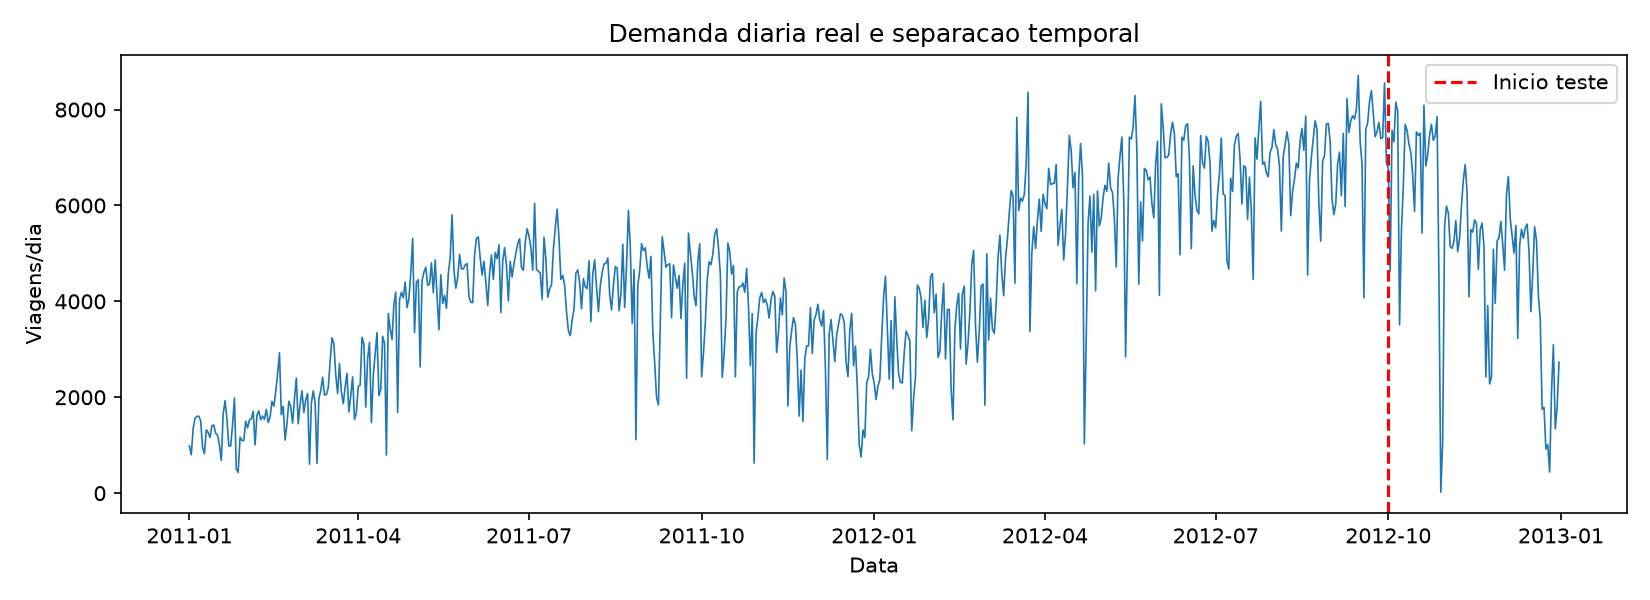

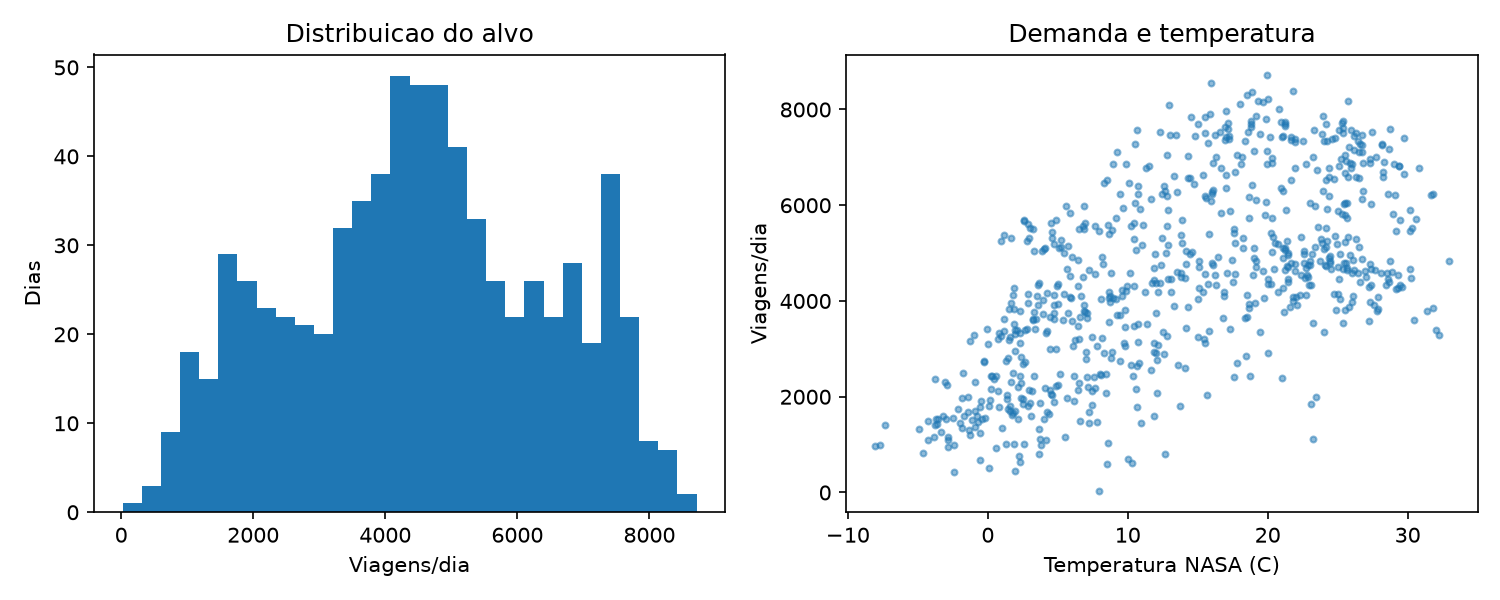

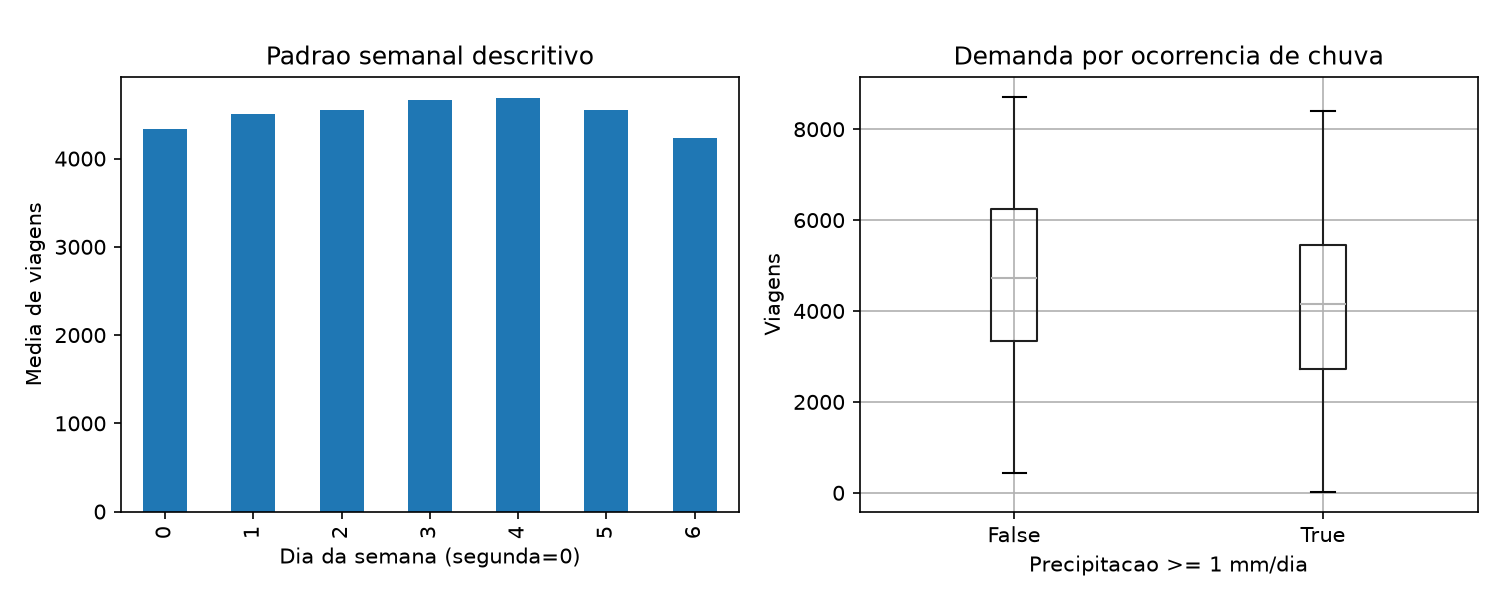

In [4]:
from IPython.display import Image,display
data=pd.read_csv(root/"data/processed/dataset_integrado.csv",parse_dates=["data"])
display(data.describe(include="all"))
for name in ["serie_temporal","eda_demanda","eda_calendario_clima"]:
    display(Image(filename=str(root/f"reports/figures/{name}.png")))

## 5. Engenharia de features e prevenção de vazamento
17 variáveis antes do encoding. Calendário, tendência e transformações meteorológicas. `cnt`, `casual`, `registered`, seus equivalentes traduzidos e identificadores não são preditores. O modelo não recebe o clima da UCI: usa somente a NASA. Imputação, StandardScaler e one-hot são ajustados em cada fold. O arquivo `docs/FEATURES.md` documenta unidades e fórmulas.

# Dicionário de features

Alvo: `viagens`, contagem diária total de aluguéis, UCI `cnt`. Unidade: viagens/dia.

| Feature | Fonte / cálculo | Significado e preparação |
|---|---|---|
| dias_desde_inicio | data - 01/01/2011 | Tendência de crescimento do sistema; escala padronizada |
| mes_sin | sin(2π × mês / 12) | Sazonalidade cíclica |
| mes_cos | cos(2π × mês / 12) | Complemento da sazonalidade mensal |
| dia_ano_sin | sin(2π × (dia do ano - 1) / 365,25) | Sazonalidade anual suavizada; aproximação para anos bissextos |
| dia_ano_cos | cos(2π × (dia do ano - 1) / 365,25) | Complemento da sazonalidade anual |
| fim_de_semana | dia da semana >= 5 | Diferença de comportamento semanal |
| temperatura | NASA T2M | Temperatura média diária em °C |
| umidade | NASA RH2M | Umidade relativa diária em % |
| vento | NASA WS2M | Velocidade média do vento a 2 m em m/s |
| precipitacao | NASA PRECTOTCORR | Precipitação corrigida diária em mm/dia |
| temperatura_quadrado | temperatura² | Permite rel

,dias_desde_inicio,mes_sin,mes_cos,dia_ano_sin,dia_ano_cos,fim_de_semana,temperatura,umidade,vento,precipitacao,temperatura_quadrado,chuva,log_precipitacao,dia_semana,mes,feriado,dia_util
0,0,0.5,0.866025,0.000000,1.000000,1,3.80,97.55,2.65,0.06,14.4400,0.0,0.058269,5,1,False,False
1,1,0.5,0.866025,0.017202,0.999852,1,3.64,86.49,2.96,3.24,13.2496,1.0,1.444563,6,1,False,False
2,2,0.5,0.866025,0.034398,0.999408,0,-1.81,69.50,3.08,0.00,3.2761,0.0,0.000000,0,1,False,True
3,3,0.5,0.866025,0.051584,0.998669,0,-0.22,80.79,2.40,0.00,0.0484,0.0,0.000000,1,1,False,True
4,4,0.5,0.866025,0.068755,0.997634,0,-0.74,74.98,2.35,0.00,0.5476,0.0,0.000000,2,1,False,True


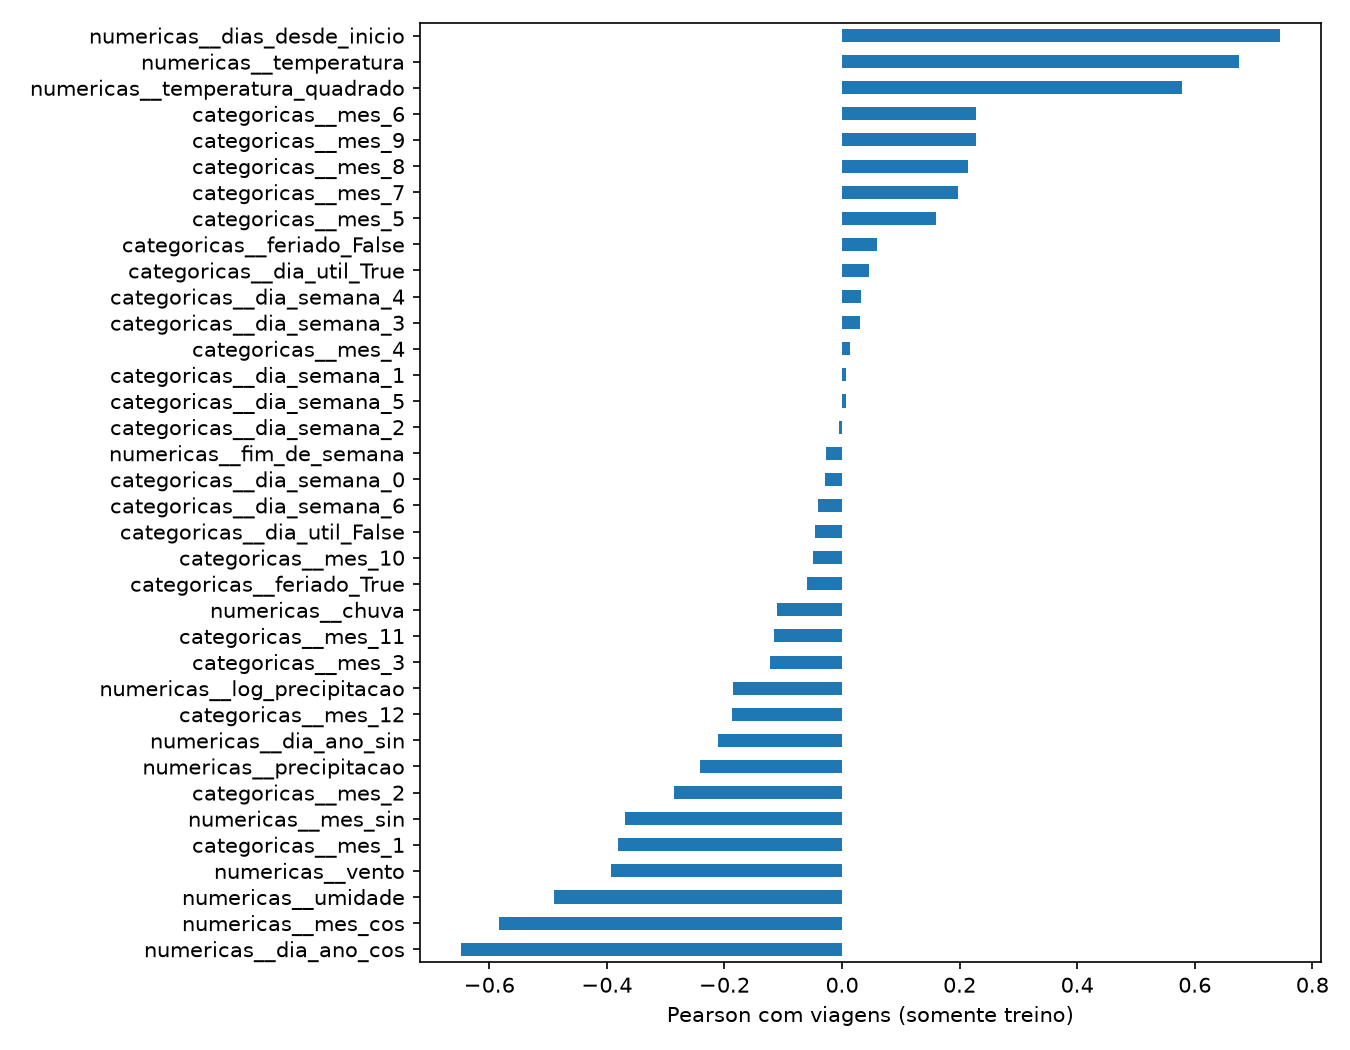

In [5]:
print((root/"docs/FEATURES.md").read_text(encoding="utf-8"))
from src.train import make_features
display(make_features(data).head())
display(Image(filename=str(root/"reports/figures/correlacoes.png")))

## 6. Desenho de avaliação
Treino: 01/01/2011–30/09/2012 (639 dias). Teste reservado: 01/10/2012–31/12/2012 (92 dias). CV: cinco janelas de validação com 90 dias e treino expansivo, sem embaralhamento. Sem lags/alvos sobrepostos, não há necessidade de embargo entre folds. Critério: menor RMSE médio de CV. Comparação: Ridge, Random Forest, Gradient Boosting e média histórica. Limiar de chuva de 1 mm e hiperparâmetros são fixos. Não se otimiza pelo resultado do teste.

,modelo,cv_rmse,cv_rmse_std,cv_mae
0,Ridge,931.416900,306.698052,753.298324
1,Gradient Boosting,1009.773358,309.654036,817.958336
2,Random Forest,1045.908285,357.893658,845.837770
3,Baseline media,2064.511906,816.863286,1856.191240


,fold,treino_inicio,treino_fim,validacao_inicio,validacao_fim,n_treino,n_validacao,modelo,rmse,mae
0,1,2011-01-01,2011-07-08,2011-07-09,2011-10-06,189,90,Ridge,770.085945,603.979568
1,2,2011-01-01,2011-10-06,2011-10-07,2012-01-04,279,90,Ridge,712.217474,572.763760
2,3,2011-01-01,2012-01-04,2012-01-05,2012-04-03,369,90,Ridge,1539.878311,1275.136981
3,4,2011-01-01,2012-04-03,2012-04-04,2012-07-02,459,90,Ridge,821.970475,655.994272
4,5,2011-01-01,2012-07-02,2012-07-03,2012-09-30,549,90,Ridge,812.932295,658.617038
5,1,2011-01-01,2011-07-08,2011-07-09,2011-10-06,189,90,Random Forest,862.838400,632.660743
6,2,2011-01-01,2011-10-06,2011-10-07,2012-01-04,279,90,Random Forest,782.767493,590.389260
7,3,2011-01-01,2012-01-04,2012-01-05,2012-04-03,369,90,Random Forest,1755.176501,1515.600332
8,4,2011-01-01,2012-04-03,2012-04-04,2012-07-02,459,90,Random Forest,911.165887,714.515501
9,5,2011-01-01,2012-07-02,2012-07-03,2012-09-30,549,90,Random Forest,917.593144,776.023013


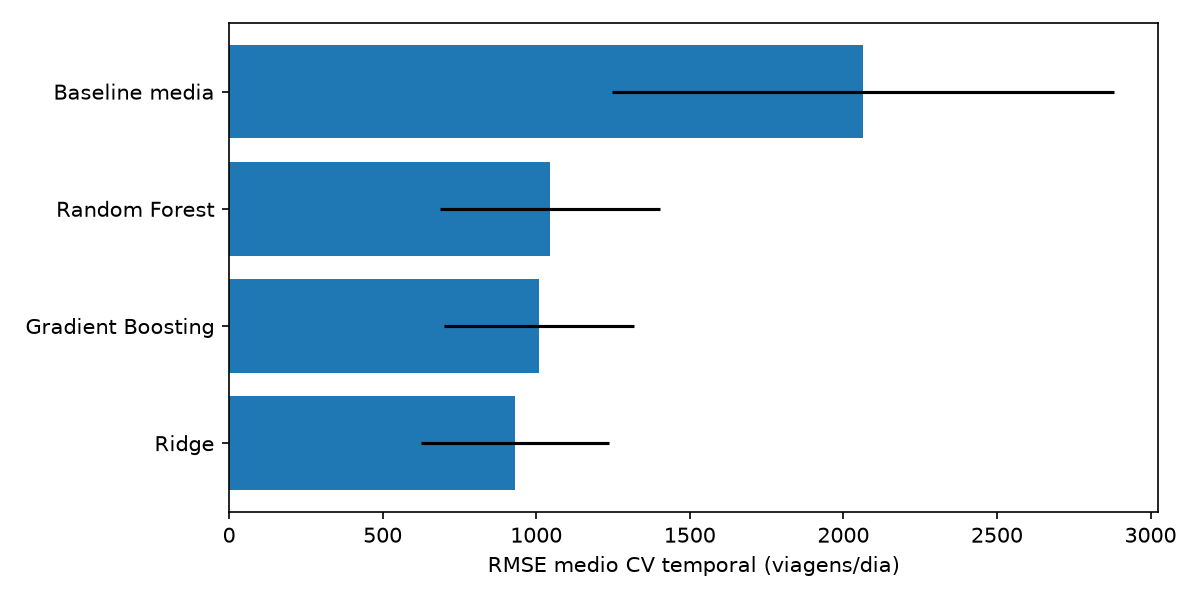

In [6]:
cv=pd.read_csv(root/"reports/metrics/comparacao_cv.csv")
folds=pd.read_csv(root/"reports/metrics/folds.csv")
display(cv)
display(folds)
display(Image(filename=str(root/"reports/figures/comparacao_modelos.png")))

## 7. Resultados reservados e contribuição da segunda fonte
RMSE penaliza erros grandes; MAE expressa o erro absoluto típico na unidade viagens/dia; R² compara o erro quadrático com a variação do alvo. Accuracy/F1 não se aplicam a esta regressão. A ablação compara Ridge com calendário versus calendário+clima usando somente CV do treino.

,n,inicio,fim,rmse,mae,r2
Modelo escolhido,92.0,2012-10-01,2012-12-31,1251.429643,848.981296,0.574961
Baseline media,NaN,NaN,NaN,2063.115915,1755.022624,-0.155216


Modelo: Ridge
Reducao de RMSE vs baseline: 39.34%


{'ridge_calendario_cv_rmse': 1191.6394653427476,
 'ridge_calendario_clima_cv_rmse': 931.4168998896068,
 'objetivo': 'Medir contribuicao da fonte meteorologica em validacao temporal de treino; nao selecionar pelo teste.'}

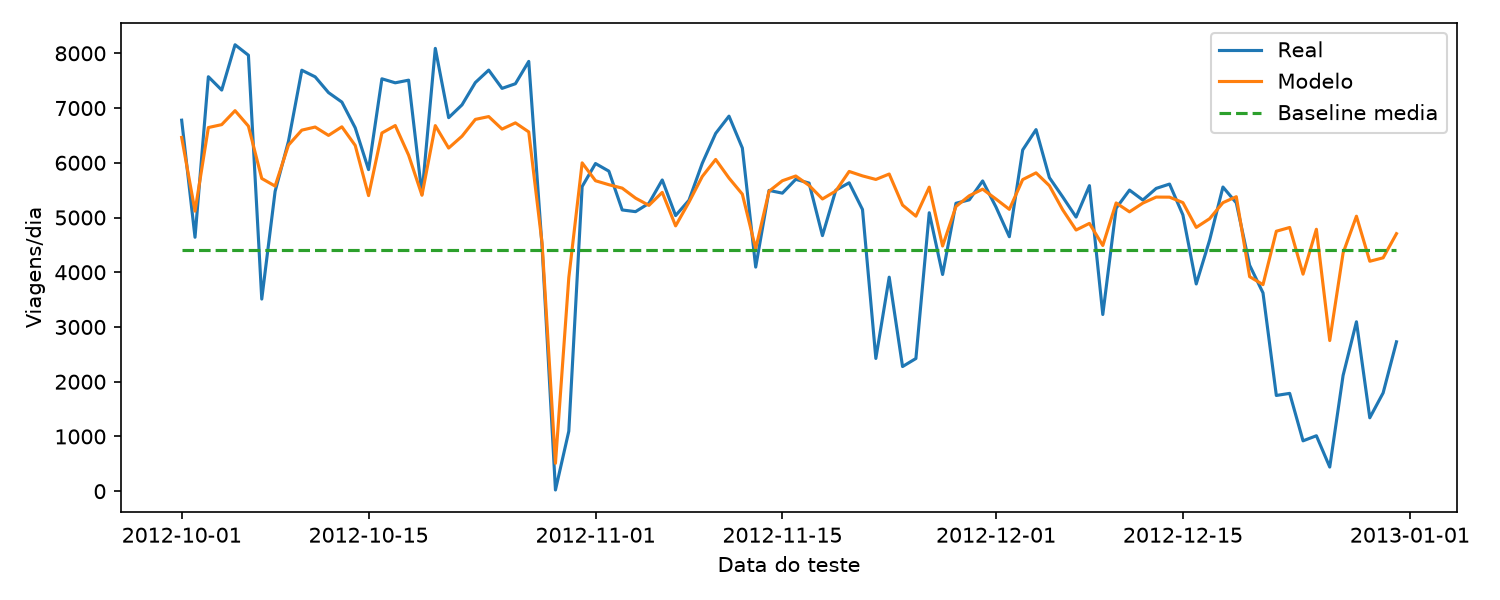

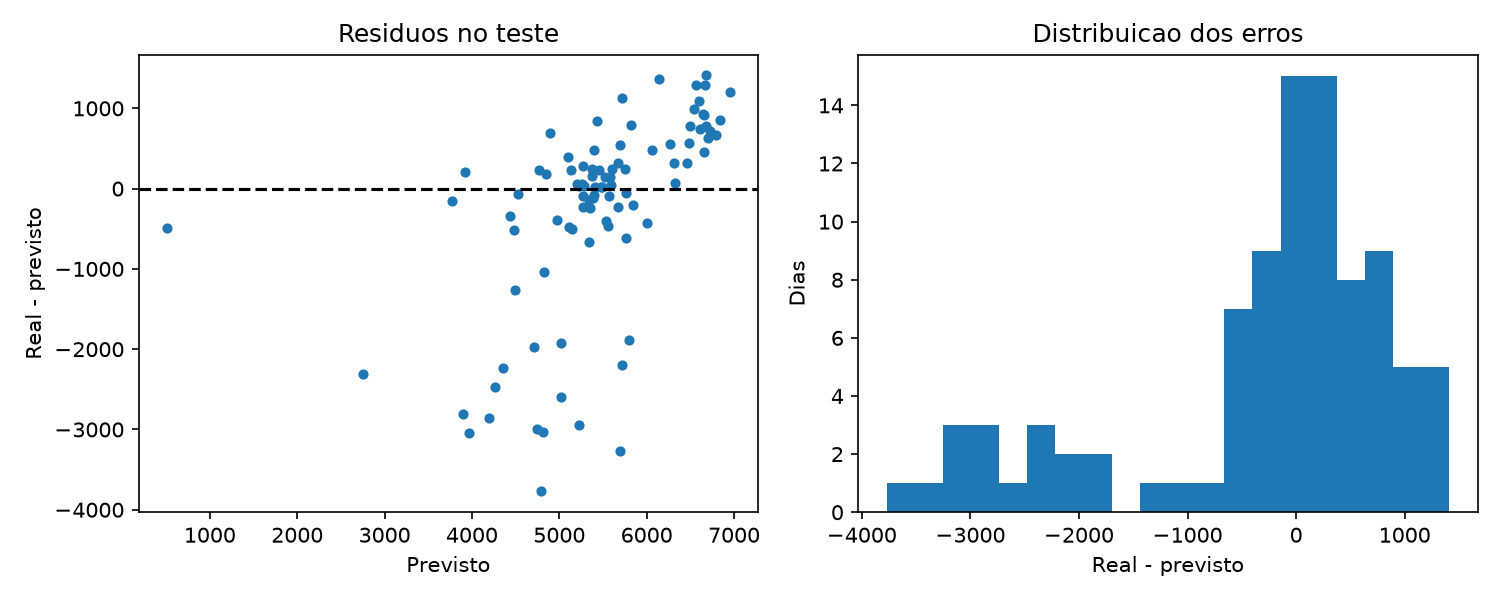

,mes,rmse,mae,r2
0,2012-10,1000.913322,807.089997,0.725454
1,2012-11,1064.855224,618.405973,0.080918
2,2012-12,1596.415892,1114.010005,0.190100


,data,real,previsto,baseline_media,residuo,erro_absoluto
85,2012-12-25,1013,4785.065848,4409.172144,-3772.065848,3772.065848
52,2012-11-22,2425,5695.428551,4409.172144,-3270.428551,3270.428551
84,2012-12-24,920,3965.259073,4409.172144,-3045.259073,3045.259073
83,2012-12-23,1787,4817.843708,4409.172144,-3030.843708,3030.843708
82,2012-12-22,1749,4749.407138,4409.172144,-3000.407138,3000.407138


In [7]:
resultado=json.loads((root/"reports/metrics/resultados.json").read_text(encoding="utf-8"))
display(pd.DataFrame([resultado["teste"],resultado["baseline_teste"]],index=["Modelo escolhido","Baseline media"]))
print("Modelo:",resultado["modelo_escolhido"])
print("Reducao de RMSE vs baseline: %.2f%%" % resultado["reducao_rmse_vs_baseline_pct"])
display(resultado["ablacao"])
for name in ["predicoes","residuos"]:display(Image(filename=str(root/f"reports/figures/{name}.png")))
display(pd.read_csv(root/"reports/metrics/metricas_mensais.csv"))
pred=pd.read_csv(root/"reports/metrics/predicoes_teste.csv")
display(pred.assign(erro_absoluto=pred.residuo.abs()).nlargest(5,"erro_absoluto"))

## 8. Interpretação e limites
A documentação `docs/RESULTADOS.md` registra a leitura quantitativa, maiores erros e comparação com baseline. O erro varia ao longo do trimestre; dias atípicos e expansão do sistema não são totalmente explicados. Associação meteorológica não demonstra causalidade. O desvio dos folds mede variação entre janelas, não intervalo de confiança. A ablação estima contribuição dentro deste desenho e não garante ganho em outra cidade.

Há apenas dois anos e um sistema. Reanálise meteorológica do próprio dia exige uso retrospectivo; não se promete previsão operacional. O modelo final continua ajustado somente no treino para preservar a avaliação. Não houve reajuste no teste ou publicação de serviço. Uma implantação exigiria dados atuais, validação externa e controles de operação.

## 9. Verificações reais e artefatos
As verificações abaixo testam integridade das fontes, ausência de sobreposição temporal, uso efetivo da NASA, ajuste do scaling no treino, recarga do modelo e constraints reais no banco. Testes de constraints são revertidos, preservando dados. O dump permite restauração em outro banco.

In [8]:
from validate import validate
validacao=validate()
display(validacao)
import joblib
model=joblib.load(root/"models/demanda_bicicletas.pkl")
print(model)
from export_database import export
export()

{
  "aprovado": true,
  "verificacoes": {
    "snapshots_sha256": true,
    "split_temporal_sem_sobreposicao": true,
    "features_sem_alvo_ou_parcelas": true,
    "join_um_para_um": true,
    "modelo_recarregado_mesmas_predicoes": true,
    "scaling_ajustado_somente_treino": true,
    "nasa_efetivamente_utilizada": true,
    "features_independem_do_alvo": true,
    "sql_confere_csv": true,
    "pk_impede_duplicata": true,
    "check_impede_contagem_incoerente": true,
    "fk_impede_localidade_orfa": true
  }
}


{'aprovado': True,
 'verificacoes': {'snapshots_sha256': True,
  'split_temporal_sem_sobreposicao': True,
  'features_sem_alvo_ou_parcelas': True,
  'join_um_para_um': True,
  'modelo_recarregado_mesmas_predicoes': True,
  'scaling_ajustado_somente_treino': True,
  'nasa_efetivamente_utilizada': True,
  'features_independem_do_alvo': True,
  'sql_confere_csv': True,
  'pk_impede_duplicata': True,
  'check_impede_contagem_incoerente': True,
  'fk_impede_localidade_orfa': True}}

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaling',
                                                                   StandardScaler())]),
                                                  ['dias_desde_inicio',
                                                   'mes_sin', 'mes_cos',
                                                   'dia_ano_sin', 'dia_ano_cos',
                                                   'fim_de_semana',
                                                   'temperatura', 'umidade',
                                                   'vento', 'precipitacao',
                                                   'temperatura_quadrado',
                              

Dump exportado: sql/mobilidade_dump.sql


## 10. Conclusão
O projeto integra coleta de duas instituições independentes, banco relacional, ETL Python, features, regressão e avaliação temporal reproduzível. Os arquivos de métricas e as saídas anteriores são a evidência de execução. Para repetir ou enviar, consulte README.md. Entrega no Moodle: URL acessível do repositório Git e este arquivo .ipynb.